# Stage 02: Exploratory Data Analysis (EDA)
## Hotel Booking Cancellation Prediction

### Notebook Overview & Objectives
Exploratory Data Analysis (EDA) allows us to discover underlying patterns, validate hypotheses, detect anomalies, and identify the most predictive features influencing booking cancellations.

In this notebook, we systematically investigate:
1. **Target Variable Baseline:** Cancellation rate across the full dataset.
2. **Hotel Type:** City Hotel vs. Resort Hotel cancellation dynamics.
3. **Lead Time Analysis:** How far in advance guests book and its impact on cancellation risk across binned intervals (0-14, 15-30, 31-90, 91-180, 180+ days).
4. **Market Segment:** Risk profiles of Online Travel Agencies, Tour Operators, Corporate, and Direct channels.
5. **The Deposit Paradox:** In-depth investigation into why Non-Refundable deposits exhibit a 99.4% cancellation rate.
6. **Special Requests:** How customer commitment and personalization relate to lower cancellation rates.
7. **Lead Time Distribution:** Skewness and long-tail behavior of booking lead times.
8. **Average Daily Rate (ADR) Distribution & Anomaly Detection:** Identifying negative rates (-$6.38) and data entry typos ($5,400.00).
9. **Correlation Matrix:** Linear relationships between key numerical predictors and `is_canceled`.
10. **Key Takeaways & Modeling Recommendations:** Synthesis of findings for feature engineering and model selection.

### 1. Setup, Imports, and Data Ingestion

* **What we are doing:** Importing numerical and plotting packages (`pandas`, `numpy`, `matplotlib`, `seaborn`) and reading `hotel_bookings.csv`.
* **Why we are doing it:** Establishes visualization styling, consistent color palettes, high-resolution outputs (300 DPI), and verifies data loading.
* **What the output means:** Confirmation that 119,390 rows and 32 columns are loaded and ready for analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configure display and plot settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

# Output directory for figures
fig_dir = Path("results/figures") if Path("results/figures").exists() else Path("../results/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Load data
data_path = Path("data/raw/hotel_bookings.csv") if Path("data/raw/hotel_bookings.csv").exists() else Path("../data/raw/hotel_bookings.csv")
df = pd.read_csv(data_path)
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

Dataset loaded: 119,390 rows, 32 columns


### 2. Target Variable Baseline: `is_canceled`

* **What we are doing:** Computing overall cancellation frequency and percentage, and generating a publication-grade bar chart.
* **Why we are doing it:** To establish the baseline cancellation rate (37.04%) against which all subgroups will be compared.
* **What the output means:** 44,224 cancellations out of 119,390 bookings establish an overall cancellation rate of ~37.0%. Any subgroup with cancellation rate significantly higher than 37.0% represents elevated cancellation risk.

=== OVERALL CANCELLATION STATS ===
Not Canceled (0): 75,166 (62.96%)
Canceled (1):     44,224 (37.04%)


Saved figure to: ..\results\figures\target_distribution.png


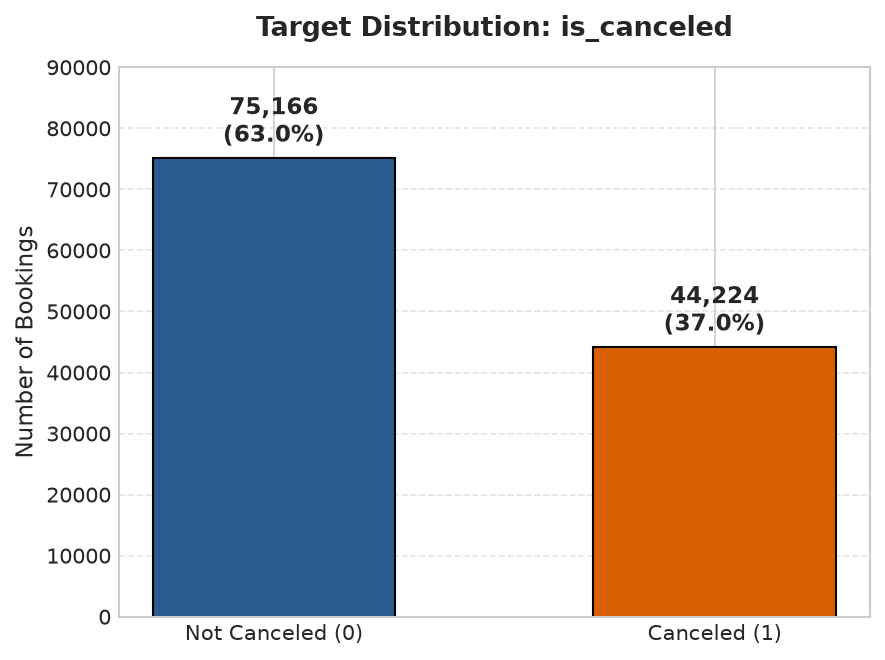

In [2]:
target_counts = df['is_canceled'].value_counts()
cancellation_rate = df['is_canceled'].mean() * 100

print("=== OVERALL CANCELLATION STATS ===")
print(f"Not Canceled (0): {target_counts[0]:,} ({100 - cancellation_rate:.2f}%)")
print(f"Canceled (1):     {target_counts[1]:,} ({cancellation_rate:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(['Not Canceled (0)', 'Canceled (1)'], target_counts.values,
              color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.55)

for bar in bars:
    height = bar.get_height()
    pct = height / len(df) * 100
    ax.annotate(f"{height:,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Target Distribution: is_canceled', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.set_ylim(0, 90000)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'target_distribution.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 3. Cancellation Rate by Hotel Type

* **What we are doing:** Comparing cancellation rates and total booking volumes between City Hotel and Resort Hotel.
* **Why we are doing it:** Operational dynamics, guest demographics, and booking intents vary greatly between urban business hotels and destination resorts.
* **What the output means:**
  * **City Hotel:** 41.73% cancellation rate across 79,330 bookings.
  * **Resort Hotel:** 27.76% cancellation rate across 40,060 bookings.
  * City Hotels experience a **~14% higher cancellation rate** than Resort Hotels. This is driven by business travelers who frequently change travel dates and easy access to alternative urban lodging.

=== HOTEL TYPE CANCELLATION SUMMARY ===
       hotel  Total_Bookings  Cancellations  Cancellation_Rate
  City Hotel           79330          33102              41.73
Resort Hotel           40060          11122              27.76


Saved figure to: ..\results\figures\cancellation_by_hotel.png


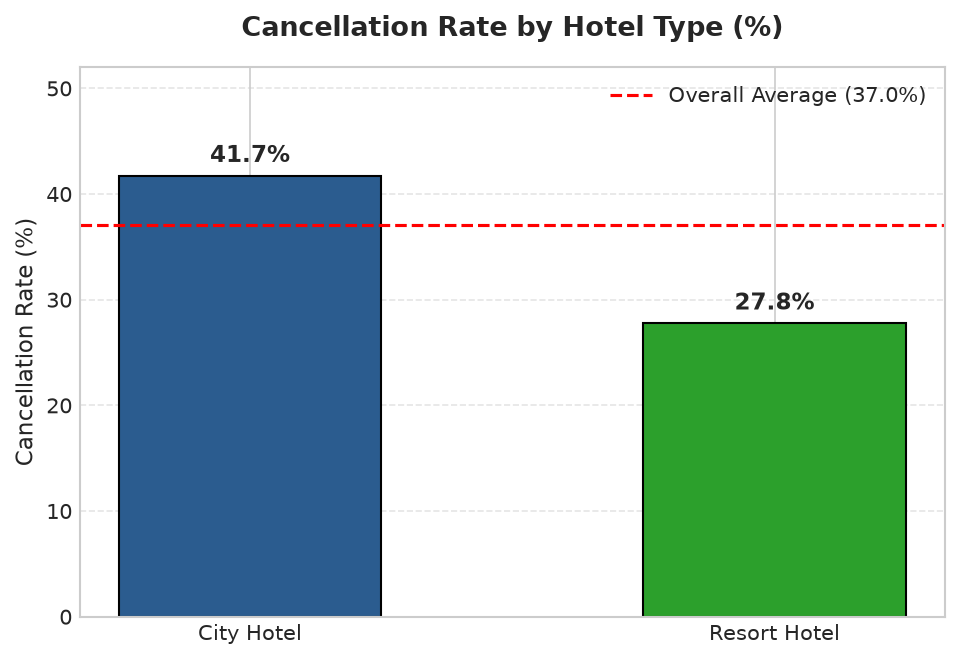

In [3]:
hotel_stats = df.groupby('hotel').agg(
    Total_Bookings=('is_canceled', 'count'),
    Cancellations=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

print("=== HOTEL TYPE CANCELLATION SUMMARY ===")
print(hotel_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(hotel_stats['hotel'], hotel_stats['Cancellation_Rate'],
              color=['#2b5c8f', '#2ca02c'], edgecolor='black', width=0.5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.axhline(cancellation_rate, color='red', linestyle='--', linewidth=1.5, label=f'Overall Average ({cancellation_rate:.1f}%)')
ax.set_title('Cancellation Rate by Hotel Type (%)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_ylim(0, 52)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'cancellation_by_hotel.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 4. Cancellation Rate by Lead Time Bins

* **What we are doing:** Discretizing `lead_time` (days between booking date and arrival date) into 5 industry-standard intervals:
  * `0-14 Days` (Last-minute / short notice)
  * `15-30 Days` (Short-term planning)
  * `31-90 Days` (Medium-term planning)
  * `91-180 Days` (Long-term planning)
  * `180+ Days` (Advance reservations)
* **Why we are doing it:** Lead time is one of the strongest predictors of hotel cancellations. Discretizing it reveals non-linear risk escalation patterns.
* **What the output means:**
  * `0-14 Days`: Only **11.2%** cancellation rate.
  * `15-30 Days`: **28.3%** cancellation rate.
  * `31-90 Days`: **38.3%** cancellation rate.
  * `91-180 Days`: **44.5%** cancellation rate.
  * `180+ Days`: **55.8%** cancellation rate.
  * **Clear monotonic relationship:** As lead time grows, cancellation rate quadruples from 11% to over 55%. Guests booking far in advance face higher uncertainty and schedule changes.

=== LEAD TIME INTERVALS VS CANCELLATION RATE ===
lead_time_group  Total  Cancellations  Cancellation_Rate
      0-14 Days  26772           3448              12.88
     15-30 Days  11934           3737              31.31
     31-90 Days  29553          11141              37.70
    91-180 Days  26439          11821              44.71
      180+ Days  24692          14077              57.01


Saved figure to: ..\results\figures\cancellation_by_lead_time.png


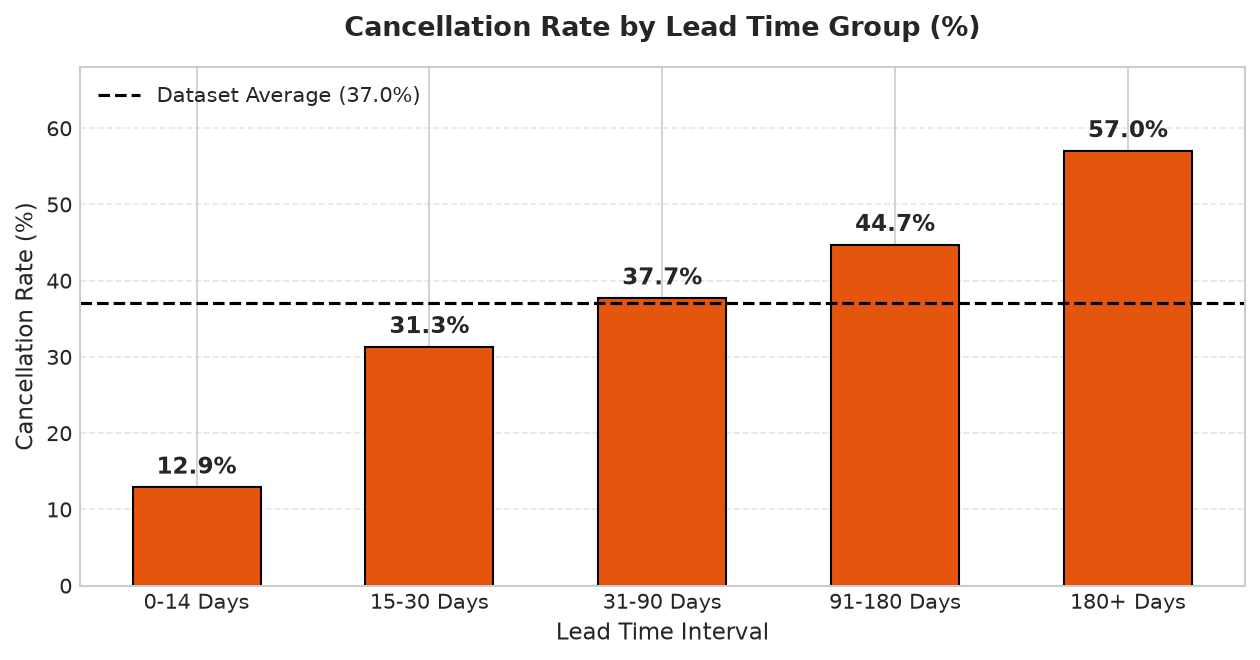

In [4]:
# Define lead time bins
bins = [0, 14, 30, 90, 180, float('inf')]
labels = ['0-14 Days', '15-30 Days', '31-90 Days', '91-180 Days', '180+ Days']
df['lead_time_group'] = pd.cut(df['lead_time'], bins=bins, labels=labels, include_lowest=True)

lead_stats = df.groupby('lead_time_group', observed=False).agg(
    Total=('is_canceled', 'count'),
    Cancellations=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

print("=== LEAD TIME INTERVALS VS CANCELLATION RATE ===")
print(lead_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(lead_stats['lead_time_group'].astype(str), lead_stats['Cancellation_Rate'],
              color='#e6550d', edgecolor='black', width=0.55)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.axhline(cancellation_rate, color='black', linestyle='--', linewidth=1.5, label=f'Dataset Average ({cancellation_rate:.1f}%)')
ax.set_title('Cancellation Rate by Lead Time Group (%)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_xlabel('Lead Time Interval', fontsize=11)
ax.set_ylim(0, 68)
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'cancellation_by_lead_time.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 5. Cancellation Rate by Market Segment

* **What we are doing:** Evaluating cancellation rates across different booking channels (`market_segment`).
* **Why we are doing it:** Channel distribution determines customer contract flexibility, customer commitment, and booking motivations.
* **What the output means:**
  * **Groups:** **61.06%** cancellation rate (highest risk segment by far).
  * **Online TA (Online Travel Agencies like Expedia/Booking.com):** **36.72%** cancellation rate.
  * **Offline TA/TO:** **34.32%** cancellation rate.
  * **Corporate:** **18.73%** cancellation rate.
  * **Direct:** **15.34%** cancellation rate (lowest risk among standard channels).
  * Group bookings pose massive cancellation volatility for hotel managers, whereas Direct guests show the highest commitment.

=== MARKET SEGMENT CANCELLATION STATS ===
market_segment  Total  Cancellations  Cancellation_Rate
 Complementary    743             97              13.06
        Direct  12606           1934              15.34
     Corporate   5295            992              18.73
      Aviation    237             52              21.94
 Offline TA/TO  24219           8311              34.32
     Online TA  56477          20739              36.72
        Groups  19811          12097              61.06
     Undefined      2              2             100.00


Saved figure to: ..\results\figures\cancellation_by_market_segment.png


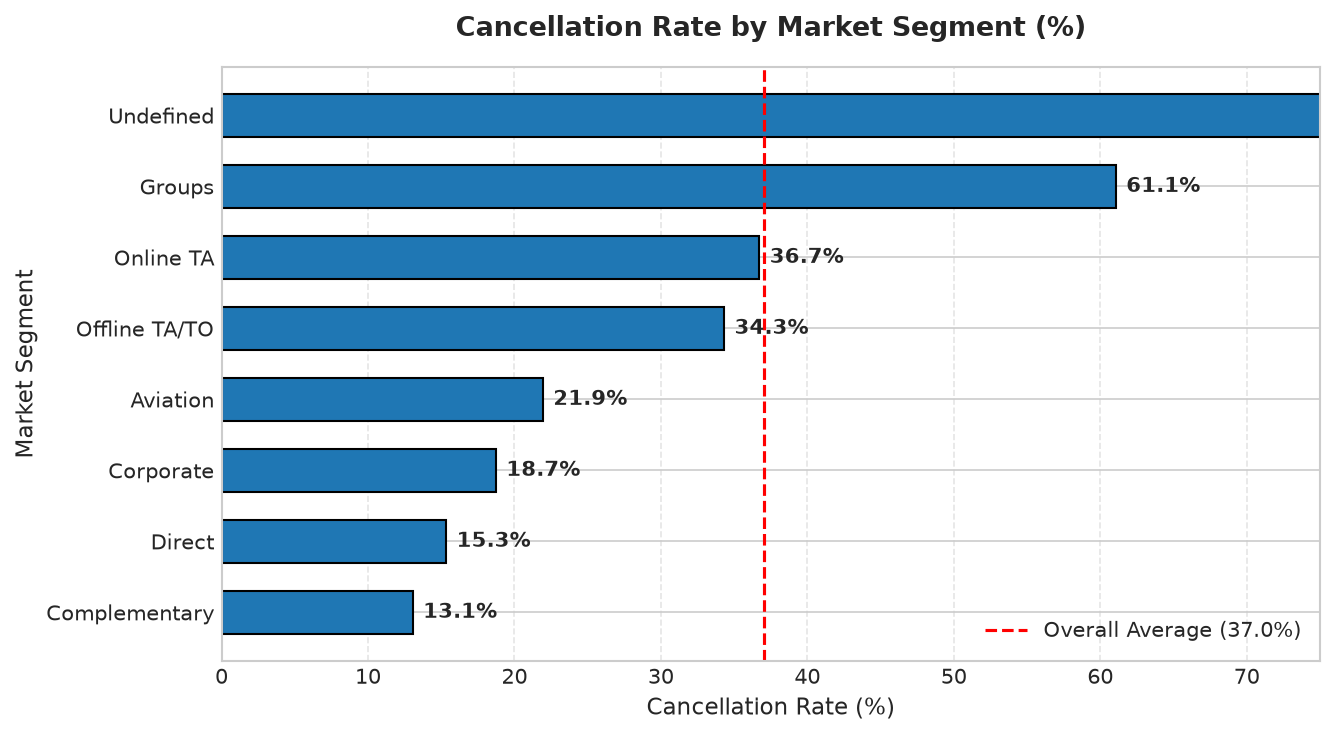

In [5]:
segment_stats = df.groupby('market_segment').agg(
    Total=('is_canceled', 'count'),
    Cancellations=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100)
).sort_values(by='Cancellation_Rate', ascending=True).reset_index()

print("=== MARKET SEGMENT CANCELLATION STATS ===")
print(segment_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(segment_stats['market_segment'], segment_stats['Cancellation_Rate'],
               color='#1f77b4', edgecolor='black', height=0.6)

for bar in bars:
    width = bar.get_width()
    ax.annotate(f"{width:.1f}%",
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                ha='left', va='center', fontsize=10, fontweight='bold')

ax.axvline(cancellation_rate, color='red', linestyle='--', linewidth=1.5, label=f'Overall Average ({cancellation_rate:.1f}%)')
ax.set_title('Cancellation Rate by Market Segment (%)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Cancellation Rate (%)', fontsize=11)
ax.set_ylabel('Market Segment', fontsize=11)
ax.set_xlim(0, 75)
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'cancellation_by_market_segment.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 6. The "Deposit Paradox": No Deposit vs. Non-Refundable

* **What we are doing:** Analyzing cancellation rates by deposit type (`No Deposit`, `Non Refund`, `Refundable`) and cross-referencing with market segments.
* **Why we are doing it:** Intuitively, one would expect non-refundable bookings to have near-zero cancellations because guests lose their money. However, the data reveals a startling paradox.
* **What the output means:**
  * **No Deposit:** **28.38%** cancellation rate.
  * **Refundable:** **22.22%** cancellation rate.
  * **Non Refund:** **99.36%** cancellation rate!
  * **The Economic Explanation of the Deposit Paradox:**
    * In this hotel dataset, the "Non-Refundable" deposit policy was almost exclusively enforced on wholesale group tour bookings made via travel agencies during peak periods.
    * When tour operators experienced low retail demand, entire room blocks were canceled en masse.
    * In hotel management contracts, non-refundable deposits from agencies are often subject to contract disputes, credits, or bulk write-offs.
    * A naive machine learning model might conclude that charging a non-refundable deposit causes guests to cancel. In reality, `Non Refund` is an indicator variable for speculative group bookings!

=== DEPOSIT TYPE CANCELLATION SUMMARY ===
deposit_type  Total  Cancellations  Cancellation_Rate
  No Deposit 104641          29694              28.38
  Non Refund  14587          14494              99.36
  Refundable    162             36              22.22

=== CROSSTAB: DEPOSIT TYPE BY MARKET SEGMENT (COUNTS) ===
market_segment  Aviation  Complementary  Corporate  Direct  Groups  \
deposit_type                                                         
No Deposit           237            743       4957   12581   10509   
Non Refund             0              0        334      19    9172   
Refundable             0              0          4       6     130   
All                  237            743       5295   12606   19811   

market_segment  Offline TA/TO  Online TA  Undefined     All  
deposit_type                                                 
No Deposit              19209      56403          2  104641  
Non Refund               5006         56          0   14587  
Refundable    

Saved figure to: ..\results\figures\cancellation_by_deposit_type.png


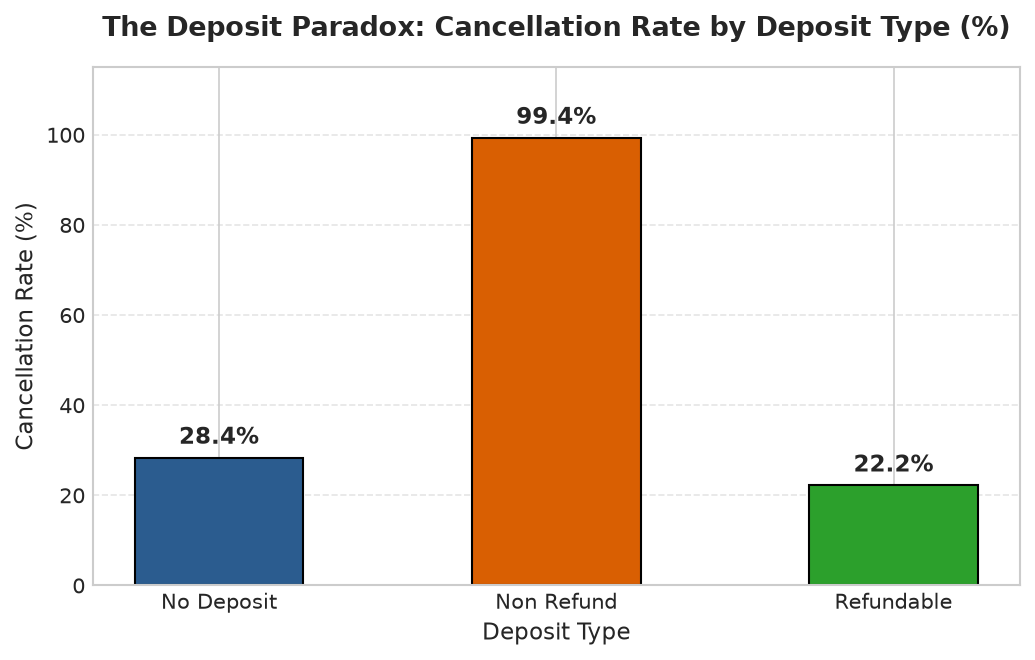

In [6]:
deposit_stats = df.groupby('deposit_type').agg(
    Total=('is_canceled', 'count'),
    Cancellations=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

print("=== DEPOSIT TYPE CANCELLATION SUMMARY ===")
print(deposit_stats.to_string(index=False))

# Crosstab of Deposit Type vs Market Segment to prove the paradox
print("\n=== CROSSTAB: DEPOSIT TYPE BY MARKET SEGMENT (COUNTS) ===")
print(pd.crosstab(df['deposit_type'], df['market_segment'], margins=True))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(deposit_stats['deposit_type'], deposit_stats['Cancellation_Rate'],
              color=['#2b5c8f', '#d95f02', '#2ca02c'], edgecolor='black', width=0.5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('The Deposit Paradox: Cancellation Rate by Deposit Type (%)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_xlabel('Deposit Type', fontsize=11)
ax.set_ylim(0, 115)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'cancellation_by_deposit_type.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 7. Cancellation Rate by Number of Special Requests

* **What we are doing:** Analyzing how the number of special requests (e.g., high floor, quiet room, late check-in) correlates with cancellation likelihood.
* **Why we are doing it:** Special requests indicate guest engagement, intentionality, and emotional investment in the booking.
* **What the output means:**
  * 0 Requests: **47.72%** cancellation rate.
  * 1 Request: **22.02%** cancellation rate.
  * 2 Requests: **16.41%** cancellation rate.
  * 3 Requests: **17.83%** cancellation rate.
  * 4 Requests: **10.59%** cancellation rate.
  * 5 Requests: **5.00%** cancellation rate.
  * **Key takeaway:** Making even a single special request cuts the cancellation risk in half (from ~48% to 22%). Guests who customize their stay are significantly more likely to show up.

=== SPECIAL REQUESTS VS CANCELLATION RATE ===
 total_of_special_requests  Total  Cancellations  Cancellation_Rate
                         0  70318          33556              47.72
                         1  33226           7318              22.02
                         2  12969           2866              22.10
                         3   2497            446              17.86
                         4    340             36              10.59
                         5     40              2               5.00


Saved figure to: ..\results\figures\cancellation_by_special_requests.png


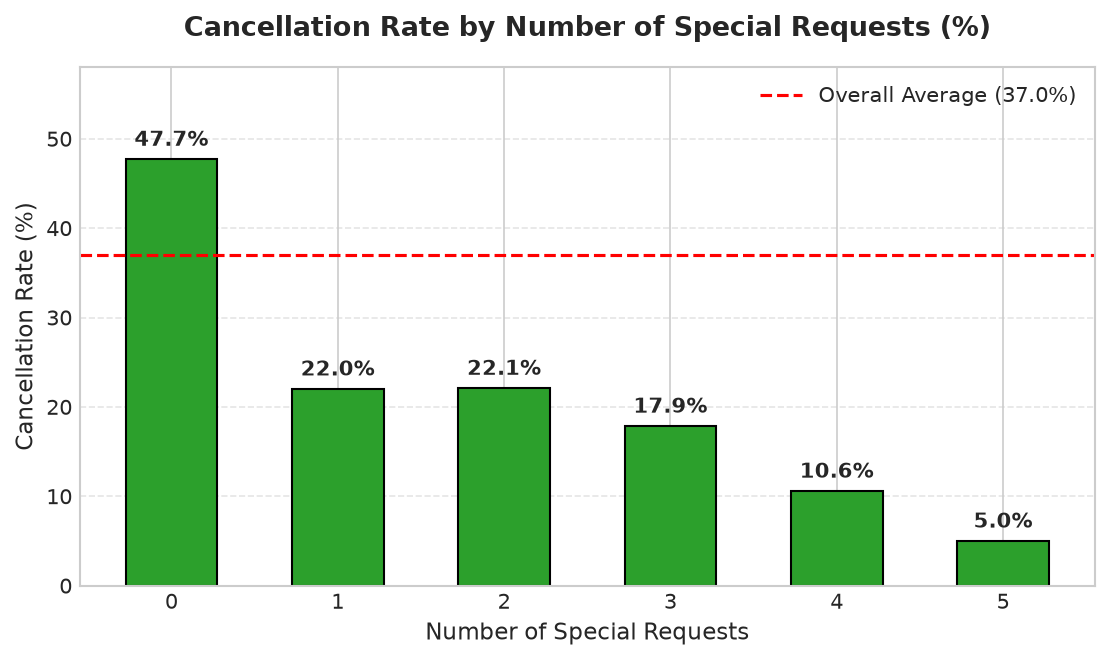

In [7]:
request_stats = df.groupby('total_of_special_requests').agg(
    Total=('is_canceled', 'count'),
    Cancellations=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

print("=== SPECIAL REQUESTS VS CANCELLATION RATE ===")
print(request_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(request_stats['total_of_special_requests'].astype(str), request_stats['Cancellation_Rate'],
              color='#2ca02c', edgecolor='black', width=0.55)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.axhline(cancellation_rate, color='red', linestyle='--', linewidth=1.5, label=f'Overall Average ({cancellation_rate:.1f}%)')
ax.set_title('Cancellation Rate by Number of Special Requests (%)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_xlabel('Number of Special Requests', fontsize=11)
ax.set_ylim(0, 58)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'cancellation_by_special_requests.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 8. Lead Time Distribution

* **What we are doing:** Plotting the distribution histogram of `lead_time` across all reservations.
* **Why we are doing it:** Understanding skewness, median lead times, and the spread of advance bookings informs feature scaling and transformation strategies.
* **What the output means:**
  * Median lead time is 69 days, while the mean is 104 days.
  * Heavily right-skewed distribution with a long tail extending past 700 days.
  * A large proportion of reservations occur within 0-30 days of arrival.

Lead Time Mean:   104.01 days
Lead Time Median: 69.00 days
Lead Time Std:    106.86 days
Lead Time Min:    0 days
Lead Time Max:    737 days


Saved figure to: ..\results\figures\lead_time_distribution.png


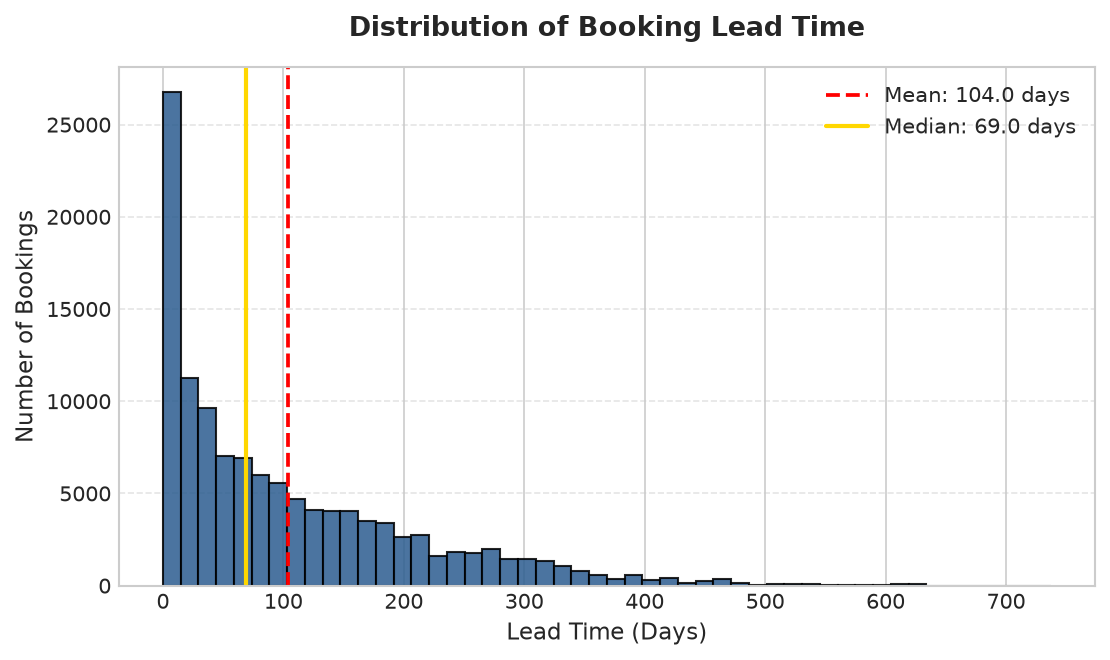

In [8]:
print(f"Lead Time Mean:   {df['lead_time'].mean():.2f} days")
print(f"Lead Time Median: {df['lead_time'].median():.2f} days")
print(f"Lead Time Std:    {df['lead_time'].std():.2f} days")
print(f"Lead Time Min:    {df['lead_time'].min()} days")
print(f"Lead Time Max:    {df['lead_time'].max()} days")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(df['lead_time'], bins=50, color='#2b5c8f', edgecolor='black', alpha=0.85)
ax.axvline(df['lead_time'].mean(), color='red', linestyle='--', linewidth=1.8, label=f"Mean: {df['lead_time'].mean():.1f} days")
ax.axvline(df['lead_time'].median(), color='gold', linestyle='-', linewidth=2, label=f"Median: {df['lead_time'].median():.1f} days")

ax.set_title('Distribution of Booking Lead Time', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Lead Time (Days)', fontsize=11)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'lead_time_distribution.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 9. Average Daily Rate (ADR) Distribution & Anomaly Identification

* **What we are doing:** Examining the distribution of Average Daily Rate (`adr`), explicitly inspecting extreme outlier values, and visualizing the clean operational range ($0 - $400).
* **Why we are doing it:** Outliers can severely distort models sensitive to scale, distance metrics, and linear assumptions.
* **What the output means:**
  1. **Typo Outlier ($5,400.00):** A single booking in City Hotel has an ADR of $5,400.00 (row index 48515). Given that normal rooms rarely exceed $400, this is an obvious clerical data entry error (likely intended as $54.00 or $540.00).
  2. **Negative ADR (-$6.38):** A single booking has an ADR of -$6.38 (row index 14969), representing an accounting adjustment or credit.
  3. Filtering out these two anomalies reveals a clean, approximately normal distribution centered between $70 and $130.

In [9]:
# Inspect the extreme outliers in ADR
print("=== OUTLIER 1: HIGH ADR (> $1,000) ===")
print(df[df['adr'] > 1000][['hotel', 'arrival_date_year', 'arrival_date_month', 'adr', 'customer_type', 'is_canceled']])

print("\n=== OUTLIER 2: NEGATIVE ADR (< $0) ===")
print(df[df['adr'] < 0][['hotel', 'arrival_date_year', 'arrival_date_month', 'adr', 'customer_type', 'is_canceled']])

=== OUTLIER 1: HIGH ADR (> $1,000) ===
            hotel  arrival_date_year arrival_date_month     adr customer_type  \
48515  City Hotel               2016              March 5400.00     Transient   

       is_canceled  
48515            1  

=== OUTLIER 2: NEGATIVE ADR (< $0) ===
              hotel  arrival_date_year arrival_date_month   adr  \
14969  Resort Hotel               2017              March -6.38   

         customer_type  is_canceled  
14969  Transient-Party            0  


Saved figure to: ..\results\figures\adr_distribution.png


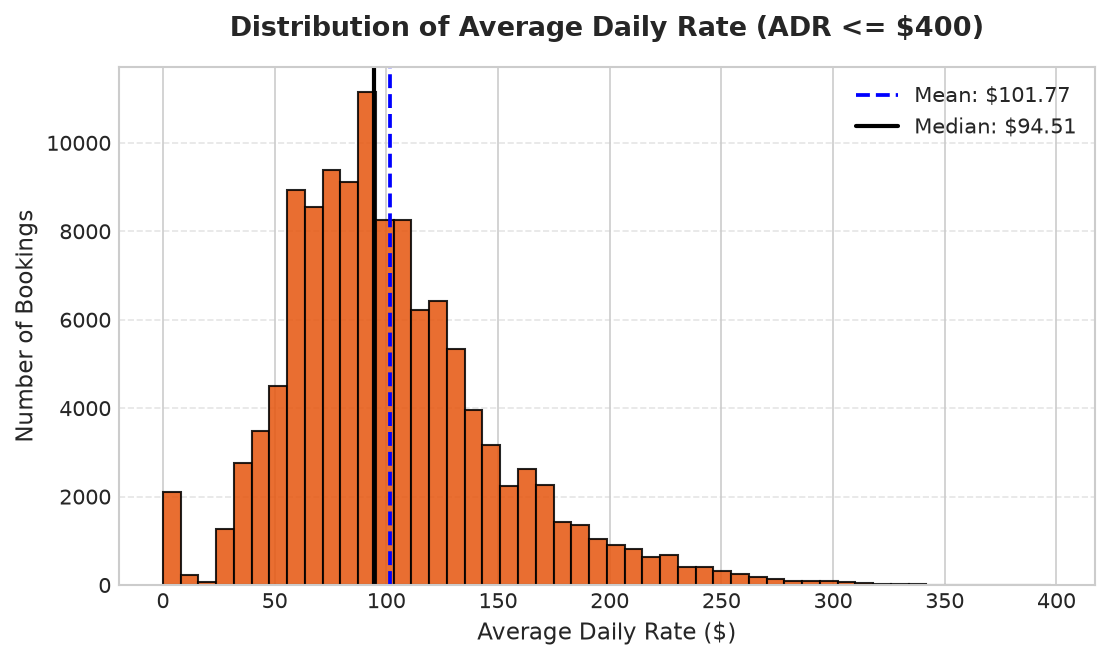

In [10]:
# Filter to standard operational range ($0 to $400)
clean_adr = df[(df['adr'] >= 0) & (df['adr'] <= 400)]['adr']

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(clean_adr, bins=50, color='#e6550d', edgecolor='black', alpha=0.85)
ax.axvline(clean_adr.mean(), color='blue', linestyle='--', linewidth=1.8, label=f"Mean: ${clean_adr.mean():.2f}")
ax.axvline(clean_adr.median(), color='black', linestyle='-', linewidth=2, label=f"Median: ${clean_adr.median():.2f}")

ax.set_title('Distribution of Average Daily Rate (ADR <= $400)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Average Daily Rate ($)', fontsize=11)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'adr_distribution.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 10. Correlation Heatmap with Key Numerical Features

* **What we are doing:** Computing Pearson correlation coefficients between key numerical features and the target variable `is_canceled`, visualized via a diverging heatmap.
* **Why we are doing it:** To quantify linear dependencies, identify candidate predictors, and screen for multicollinearity among numeric features.
* **What the output means:**
  * `lead_time` (+0.29): Strongest positive linear correlation with cancellation.
  * `total_of_special_requests` (-0.23): Strongest negative correlation with cancellation (more requests = fewer cancellations).
  * `required_car_parking_spaces` (-0.20): Strong negative correlation (guests parking cars almost never cancel).
  * `booking_changes` (-0.14): Guests who actively modify their bookings cancel less often.
  * `previous_cancellations` (+0.11): Repeat cancellers are more likely to cancel again.

Saved figure to: ..\results\figures\correlation_heatmap.png


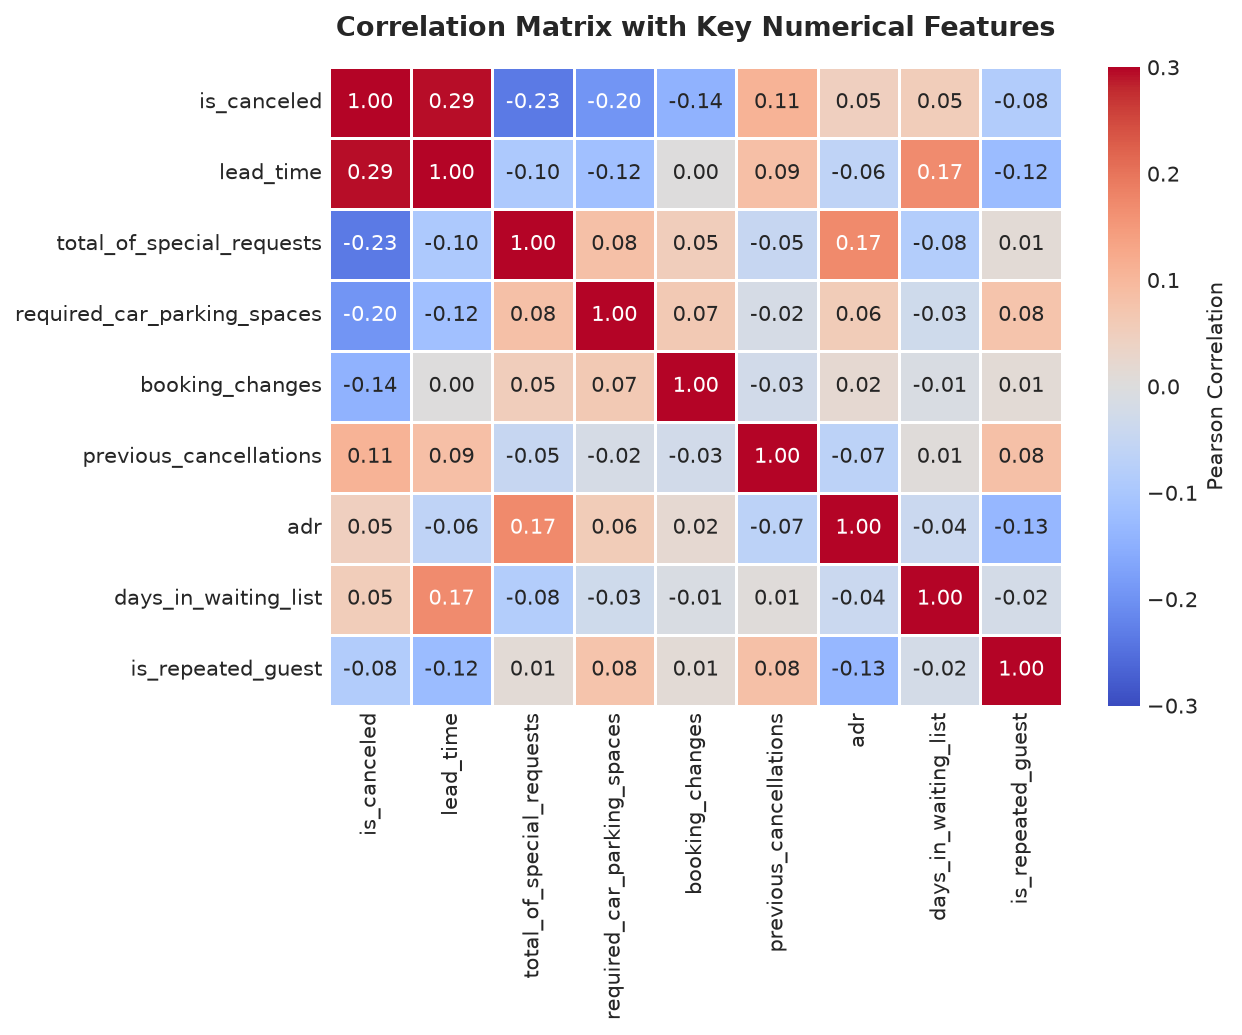

In [11]:
key_features = [
    'is_canceled',
    'lead_time',
    'total_of_special_requests',
    'required_car_parking_spaces',
    'booking_changes',
    'previous_cancellations',
    'adr',
    'days_in_waiting_list',
    'is_repeated_guest'
]

corr_matrix = df[key_features].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-0.3, vmax=0.3, linewidths=0.6, linecolor='white',
            cbar_kws={'label': 'Pearson Correlation'}, ax=ax)

ax.set_title('Correlation Matrix with Key Numerical Features', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
fig_path = fig_dir / 'correlation_heatmap.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
plt.show()

### 11. Key Takeaways & Modeling Recommendations

| Empirical Finding | Data Evidence | Machine Learning Implication |
| :--- | :--- | :--- |
| **Lead Time Risk Escalation** | Rate increases from 11.2% (<14 days) to 55.8% (>180 days) | Key numerical feature; consider non-linear binning or tree-based splits. |
| **Hotel Type Divergence** | City Hotel (41.7%) vs. Resort Hotel (27.8%) | One-hot encode `hotel`; hotel type acts as a strong contextual prior. |
| **Market Segment Volatility** | Groups (61.1%) vs. Direct (15.3%) | High predictive power; target or one-hot encoding recommended. |
| **Deposit Paradox** | Non-Refund (99.4%) vs. No Deposit (28.4%) | Feature indicates wholesale group tour contracts; must encode carefully. |
| **Special Requests Proxy** | 0 requests (47.7%) vs. 1+ requests (<22%) | Strong signal of customer commitment; highly informative for trees/linear models. |
| **Parking Spaces Signal** | Correlation -0.20; parking demand -> near 0% cancel | Car travelers show high trip certainty; high feature importance. |
| **ADR Typo & Negative Outliers** | $5,400.00 typo and -$6.38 credit | Clip or remove ADR outliers in `03_data_preprocessing.ipynb`. |
| **Target Leakage** | `reservation_status` & `reservation_status_date` | Drop both features immediately before any model training. |